# 1 次のハイパスフィルタ(HPF)

**高い周波数を通し、低い周波数を通しにくくする**回路です。[LPF](01_lpf.ipynb) と逆の働きで、ゆっくりした変化や直流を取り除くのに使います(例:センサーの信号から、ゆっくり変わる直流分を除いて変化だけを取り出す)。

この回では、正弦波を $f_c$ で入れる、方形波を入れる、直流のずれを取り除く、の 3 つを見ます。

## 回路

![1 次の HPF の回路](02_hpf/circuit.svg)

LPF の R と C を入れ替えた **CR 回路**の後ろに、ボルテージフォロワ(ゲイン 1)を置いた回路です。単電源の回路では、R の下側を信号のグランド(2.5 V、Mimic の Vref)につなぎます。

## 原理

コンデンサ C は直流を通さず、周波数が高いほど交流を通しやすくなります($Z_C = \dfrac{1}{j 2\pi f C}$)。

- 低い周波数:C がほとんど通さない → 出力は小さい(直流は 0、つまり Vref のまま)
- 高い周波数:C がよく通す → 入力がそのまま出る

$$H(f) = \frac{j\,f/f_c}{1 + j\,f/f_c}, \qquad f_c = \frac{1}{2\pi R C}$$

| 周波数 | 振幅 | 位相 |
|---|---|---|
| $f \ll f_c$ | $f / f_c$(周波数が 1/10 で 1/10、+20 dB/dec) | +90° に近づく(進む) |
| $f = f_c$ | $1/\sqrt{2} \approx 0.707$(−3 dB) | +45° |
| $f \gg f_c$ | 1(そのまま) | 0° |

![1 次の HPF の周波数特性(模式図)](02_hpf/response.svg)

**時間で見ると**:入力が急に変わると、出力も同じだけ跳ね、そのあと $e^{-t/\tau}$ の形で 0(Vref)に戻ります。時定数は LPF と同じ $\tau = RC = \dfrac{1}{2\pi f_c}$ で、$\tau$ の時間で跳ねた分の 37 %(= 100 % − 63 %)まで戻ります。

HPF の出力は、LPF の出力を入力から引いたものになっています($1 - \dfrac{1}{1 + j f/f_c} = \dfrac{j f/f_c}{1 + j f/f_c}$)。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.filter1st_hpf(fc)` | `mimic.setFilter1stHPF(fc)` | $f_c = \dfrac{1}{2\pi R C}$ |

例:$f_c$ = 100 Hz は、R = 16 kΩ、C = 0.1 µF($f_c \approx$ 99.5 Hz)の回路にあたります。時定数は $\tau \approx$ 1.59 ms です。

## 準備:測定器につなぐ

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

In [2]:
FC = 100  # cutoff frequency [Hz]
lab.mimic.filter1st_hpf(FC)

## 実験 1:正弦波を $f_c$ で入れる

表のとおりなら、出力の振幅は 0.707 倍、位相は 45° **進む**はずです(LPF では遅れました)。

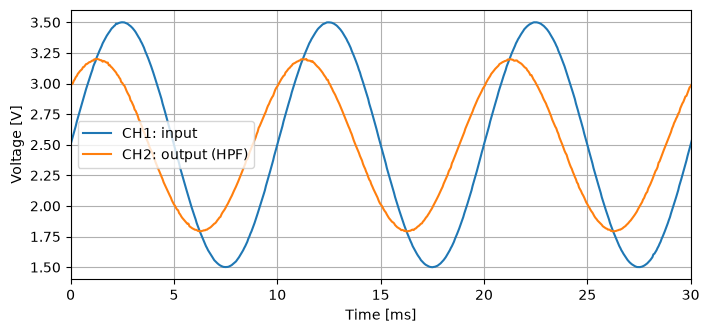

gain : 0.701   (theory 0.707)
phase: 43.3 deg (theory +45)


In [3]:
lab.fg.sine(FC, 1.0)
t, ch1, ch2 = lab.scope.capture(2000)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (HPF)")
ax.set_xlim(0, 30)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

a1, p1, c1 = fit_sine(t, ch1, FC)
a2, p2, c2 = fit_sine(t, ch2, FC)
print(f"gain : {a2 / a1:.3f}   (theory 0.707)")
print(f"phase: {(p2 - p1 + 180) % 360 - 180:.1f} deg (theory +45)")

位相は理論より少し小さく(遅れ側に)出ます。Mimic の計算の遅れのためです(LPF の回と同じ)。

## 実験 2:方形波を入れる

20 Hz の方形波を入れます。入力が切り替わるたびに出力が跳ね、そのあと Vref(2.5 V)に戻っていきます。立ち上がりのあと、跳ねた分の 37 % まで戻る時間(時定数)を読みます。

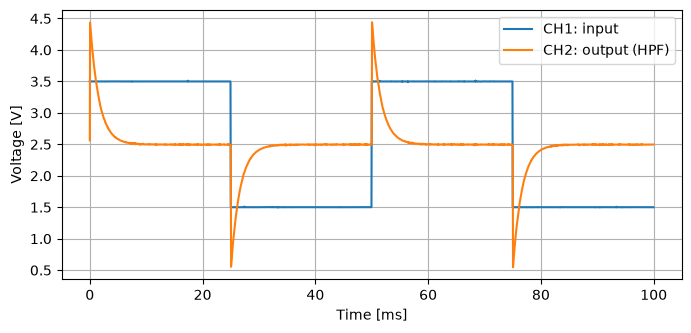

In [4]:
lab.fg.square(20, 1.0)
t, ch1, ch2 = lab.scope.capture(2000)  # 0.1 s: two periods

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (HPF)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

jump: 1.940 V (input step 2.017 V)
time constant: 1.60 ms (theory 1.59 ms)


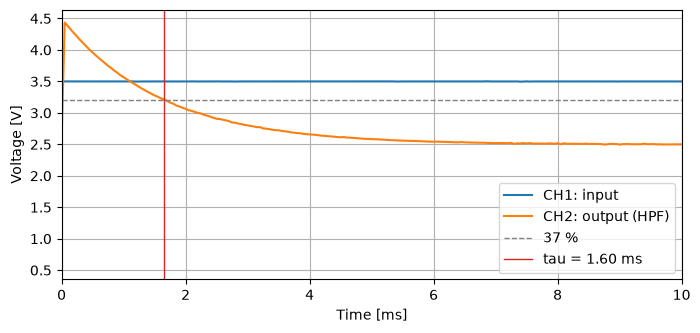

In [5]:
base = ch2[(t > 0.020) & (t < 0.024)].mean()  # settled, just before the falling edge
i_peak = int(np.argmax(ch2[t < 0.002]))       # the jump after the rising edge at t = 0
peak = ch2[i_peak]
level = base + 0.368 * (peak - base)          # 37 % of the jump
i = i_peak + int(np.argmax(ch2[i_peak:] < level))
t37 = np.interp(level, ch2[i - 1:i + 1][::-1], t[i - 1:i + 1][::-1])
tau = t37 - t[i_peak]
print(f"jump: {peak - base:.3f} V (input step {ch1.max() - ch1.min():.3f} V)")
print(f"time constant: {tau * 1e3:.2f} ms (theory {1e3 / (2 * np.pi * FC):.2f} ms)")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (HPF)")
ax.axhline(level, color="gray", ls="--", lw=1, label="37 %")
ax.axvline(t37 * 1e3, color="C3", lw=1, label=f"tau = {tau * 1e3:.2f} ms")
ax.set_xlim(0, 10)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## 実験 3:直流のずれを取り除く

中心を 3.0 V にずらした正弦波(Vref より 0.5 V 高い)を入れます。HPF は直流を通さないので、出力の中心は Vref(2.5 V)に戻ります。周波数は $f_c$ より十分高い 1 kHz にして、交流の部分はそのまま通します。

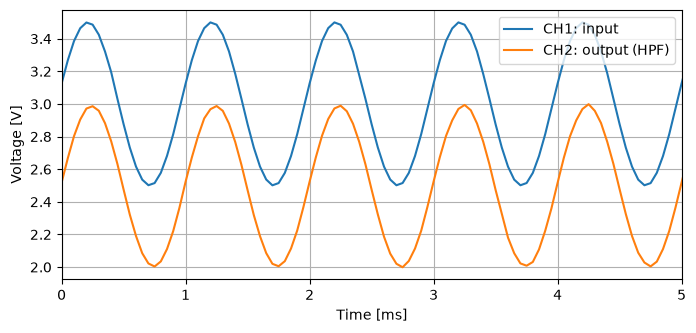

centre: input 3.001 V, output 2.496 V
gain  : 0.984


In [6]:
lab.fg.sine(1000, 0.5, 3.0)  # 1 kHz, 0.5 V peak, centre 3.0 V
t, ch1, ch2 = lab.scope.capture(400)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (HPF)")
ax.set_xlim(0, 5)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

a1, p1, c1 = fit_sine(t, ch1, 1000)
a2, p2, c2 = fit_sine(t, ch2, 1000)
print(f"centre: input {c1:.3f} V, output {c2:.3f} V")
print(f"gain  : {a2 / a1:.3f}")

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 方形波で $f_c$ を変える
<details><summary>ヒント</summary>

`FC_TRY` を 5 → 100 → 1000 と変えてみましょう。$f_c$ が高い(時定数が短い)ほど、跳ねたあとすぐ Vref に戻り、切り替わりの瞬間だけに細いとげが出ます。$f_c$ が低いと、方形波の形がほぼ残ります。

</details>

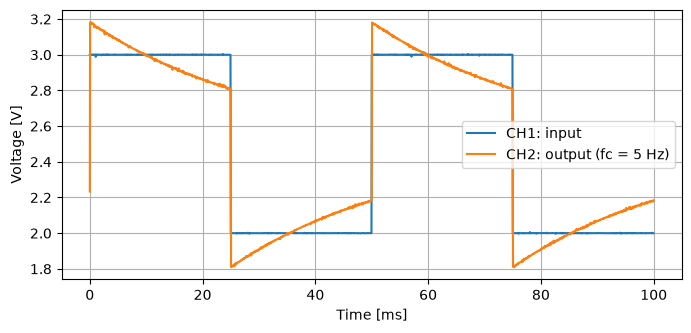

In [7]:
FC_TRY = 5   # cutoff frequency [Hz]

import time
lab.mimic.filter1st_hpf(FC_TRY)
lab.fg.square(20, 0.5)
time.sleep(0.5)
t, ch1, ch2 = lab.scope.capture(2000)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (fc = {FC_TRY} Hz)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. 中心の電圧を変える

1 kHz の正弦波の中心(オフセット)を変えて、出力の中心を見ます。
<details><summary>ヒント</summary>

`OFFSET` を 1.5 → 2.5 → 3.5 と変えてみましょう。入力は上下に動きますが、出力の中心はいつも Vref(2.5 V)のままです。HPF は直流を通さないからです。

</details>

centre: input 1.500 V, output 2.496 V


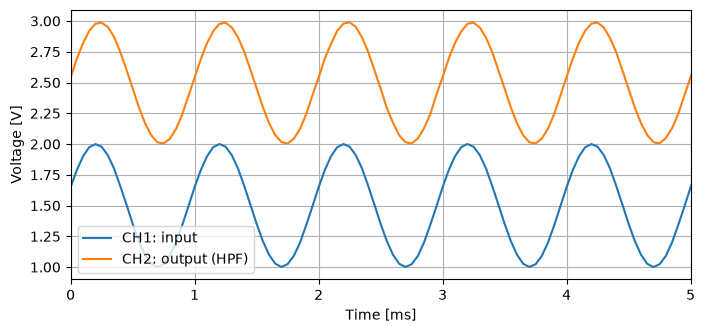

In [8]:
OFFSET = 1.5   # centre of the input [V]

import time
lab.mimic.filter1st_hpf(100)
lab.fg.sine(1000, 0.5, OFFSET)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(400)
_, _, c1 = fit_sine(t, ch1, 1000)
_, _, c2 = fit_sine(t, ch2, 1000)
print(f"centre: input {c1:.3f} V, output {c2:.3f} V")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (HPF)")
ax.set_xlim(0, 5)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 3. 三角波を、$f_c$ の高い HPF に入れる

20 Hz の三角波を HPF に入れて、$f_c$ を上げていきます。出力はどんな形になるでしょうか。
<details><summary>ヒント</summary>

`FC_HIGH` を 20 → 200 → 1000 と上げてみましょう。$f_c$ が信号の周波数よりずっと高くなると、出力は**方形波**に近い形になり、振幅は小さくなります。$f_c$ よりずっと低い周波数では、HPF は入力の変化の速さを出す**微分器**のように働くからです。三角波は上りと下りで傾きが一定なので、出力は 2 つの値を行き来します(4 章の微分器の回につながります)。

</details>

output: 1.910 - 3.096 V


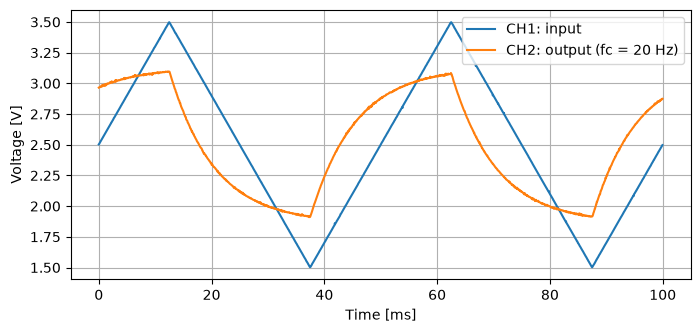

In [9]:
FC_HIGH = 20   # [Hz]

lab.mimic.filter1st_hpf(FC_HIGH)
lab.fg.triangle(20, 1.0)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (fc = {FC_HIGH} Hz)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- 1 次の HPF は、$f_c = 1/(2\pi RC)$ より低い周波数を通しにくくする。$f_c$ では振幅 0.707 倍、位相 +45°(進む)。
- 直流を通さないので、信号の直流のずれを取り除ける(出力の中心は Vref)。
- 時間で見ると、急な変化で跳ね、時定数 $\tau = RC$ で Vref に戻る。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [10]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()